# 01 · EDA — Stanford 40 Actions 8개 행동 분류

**이 노트북의 목적:** 모델을 만들기 전에 데이터를 눈과 숫자로 확인해서, 이후 실험(전처리·지표·개선 방향)의 **근거**를 만든다.

| 섹션 | 확인 내용 | 보고서 항목 |
|---|---|---|
| 1 | 파일 존재, 라벨 연결, 분할 출처 | 데이터 구조 / 라벨 연결 오류 |
| 2 | 클래스별 분포 (특히 Test 불균형) | 클래스별 분포 / **평가 지표 선정 근거** |
| 3 | 해상도·종횡비 | 이미지 특성 |
| 4 | 손상·흑백·밝기 | 품질 분석 |
| 5 | 중복·유사 이미지 (분할 간 누수) | 품질 분석 / 중복 |
| 6 | 클래스별 샘플 눈으로 보기 | 이미지 특성 |
| 7 | Crop vs Padding 비교 | **전처리 선택 근거** |

> ⚠️ 이 노트북에서 파일명(`source_filename`) 등을 쓰는 것은 **데이터 점검용**일 뿐이다. 모델 입력은 RGB 픽셀만 쓴다(규칙 4).

## 0 · 환경 설정
`DATA_DIR`을 `metadata.csv`와 `images/` 폴더가 들어 있는 위치로 바꾼 뒤 실행한다.

In [1]:
# Colab에서 Google Drive에 데이터를 올려두었다면 아래 두 줄의 주석(#)을 지우고 실행
# from google.colab import drive
# drive.mount('/content/drive')

import hashlib                      # 파일 내용이 완전히 같은지 비교할 때 사용
from pathlib import Path            # 파일 경로를 편하게 다루는 도구

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm          # 진행률 막대 표시
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()


DATA_DIR = PROJECT_ROOT / "data" / "raw"  # ← 본인 데이터 위치로 수정!
FIG_DIR = PROJECT_ROOT / "figures"                                # 보고서용 그림 저장 폴더
FIG_DIR.mkdir(exist_ok=True)
SEED = 42                                                  # 무작위 샘플을 매번 같게 뽑기 위한 번호
SPLITS = ["train", "val", "test"]

print("프로젝트 위치:", PROJECT_ROOT)

# 그래프 글자는 영어 클래스명을 쓴다 (Colab 기본 글꼴은 한글이 깨지기 때문)
plt.rcParams["figure.dpi"] = 100
def load_rgb(rel_path):
    """이미지를 RGB로 연다. 손상된 파일이면 에러로 멈추지 않고 회색 빈 그림을 돌려준다."""
    try:
        with Image.open(DATA_DIR / rel_path) as im:
            return im.convert("RGB")
    except Exception:
        return Image.new("RGB", (224, 224), (128, 128, 128))

print("데이터 폴더 존재:", DATA_DIR.exists())

프로젝트 위치: c:\Users\power\Documents\human-action-classification
데이터 폴더 존재: True


## 1 · 데이터 구조와 라벨 연결 점검
표의 숫자와 실제 파일이 맞는지, 라벨이 올바르게 붙었는지, 분할이 설명과 같은지 확인한다.
- **라벨 연결 오류 확인 방법:** 원본 파일명(`running_081.jpg`)의 앞부분은 원래 행동 이름이다. 이것이 `class_name`과 다르면 라벨이 잘못 붙은 것이다.

In [2]:
meta = pd.read_csv(DATA_DIR / "metadata.csv", encoding="utf-8-sig")   # utf-8-sig: 파일 맨 앞 보이지 않는 문자(BOM) 제거
classes = pd.read_csv(DATA_DIR / "class_mapping.csv", encoding="utf-8-sig").sort_values("target_id")
CLASS_NAMES = classes["class_name"].tolist()          # 0~7 순서의 영어 클래스명
print("메타데이터 크기:", meta.shape)
display(meta.head(3))

checks = {}
checks["결측값(빈 칸) 개수"] = int(meta.isna().sum().sum())
checks["image_id 중복"] = int(meta["image_id"].duplicated().sum())
checks["원본 파일명 중복"] = int(meta["source_filename"].duplicated().sum())
# 표에 적힌 경로에 실제 파일이 있는지
exists = meta["image_path"].map(lambda p: (DATA_DIR / p).exists())
checks["실제 파일 없음"] = int((~exists).sum())
# 원본 파일명 앞부분과 class_name 비교 → 라벨 연결 오류 확인
prefix = meta["source_filename"].str.replace(r"_\d+\.jpg$", "", regex=True)
checks["파일명-라벨 불일치"] = int((prefix != meta["class_name"]).sum())
# target_id(숫자)와 class_name(이름)의 짝이 class_mapping.csv와 같은지
merged = meta.merge(classes, on="target_id", suffixes=("", "_map"))
checks["숫자라벨-클래스명 불일치"] = int((merged["class_name"] != merged["class_name_map"]).sum())
# train/val은 원본 Train, test는 원본 Test에서 왔는지
wrong_src = ((meta["split"].isin(["train", "val"])) & (meta["original_split"] != "train")) | \
            ((meta["split"] == "test") & (meta["original_split"] != "test"))
checks["분할 출처 어긋남"] = int(wrong_src.sum())
checks["group_id 고유 개수 (전체 행 수와 비교)"] = f'{meta["group_id"].nunique()} / {len(meta)}'

for k, v in checks.items():
    print(f"{k:>30} : {v}")
display(pd.crosstab(meta["split"], meta["original_split"]))

메타데이터 크기: (2031, 12)


,image_id,image_path,split,target_id,class_name,class_name_ko,source_filename,original_split,group_id,width,height,file_size_bytes
0,s40_0004dbd129ba7b27e4e2,images/test/s40_0004dbd129ba7b27e4e2.jpg,test,5,running,달리기,running_081.jpg,test,group_s40_0004dbd129ba7b27e4e2,400,562,72862
1,s40_0010d8bdd8852b56c7bd,images/test/s40_0010d8bdd8852b56c7bd.jpg,test,6,shooting_an_arrow,활쏘기,shooting_an_arrow_160.jpg,test,group_s40_0010d8bdd8852b56c7bd,236,200,24245
2,s40_00371fc2f260232bcce5,images/train/s40_00371fc2f260232bcce5.jpg,train,2,riding_a_bike,자전거 타기,riding_a_bike_113.jpg,train,group_s40_00371fc2f260232bcce5,440,300,48375


                   결측값(빈 칸) 개수 : 0
                   image_id 중복 : 0
                     원본 파일명 중복 : 0
                      실제 파일 없음 : 0
                    파일명-라벨 불일치 : 0
                 숫자라벨-클래스명 불일치 : 0
                     분할 출처 어긋남 : 0
   group_id 고유 개수 (전체 행 수와 비교) : 2031 / 2031


original_split,test,train
split,,
test,1231,0
train,0,640
val,0,160


**해석 가이드**
- 위 점검이 모두 0이면 "라벨 연결 오류·누락 파일 없음"을 보고서에 근거와 함께 쓸 수 있다.
- `group_id`가 이미지마다 전부 다르면, 이미지 한 장이 하나의 그룹이라는 뜻이다. 즉 **같은 사람끼리 묶는 용도로 쓸 수 없고**(규칙 6), 그룹 기준 분할을 따로 할 필요도 없다.

## 2 · 클래스별 분포 → 평가 지표 선정 근거
Train/Val은 클래스별 80/20장으로 균형이지만, Test는 원본에서 왔으므로 불균형일 수 있다.

split,train,val,test,test 비율(%)
class_name,,,,
climbing,80,20,195,15.8
jumping,80,20,195,15.8
riding_a_bike,80,20,193,15.7
riding_a_horse,80,20,196,15.9
rowing_a_boat,80,20,85,6.9
running,80,20,151,12.3
shooting_an_arrow,80,20,114,9.3
throwing_frisby,80,20,102,8.3


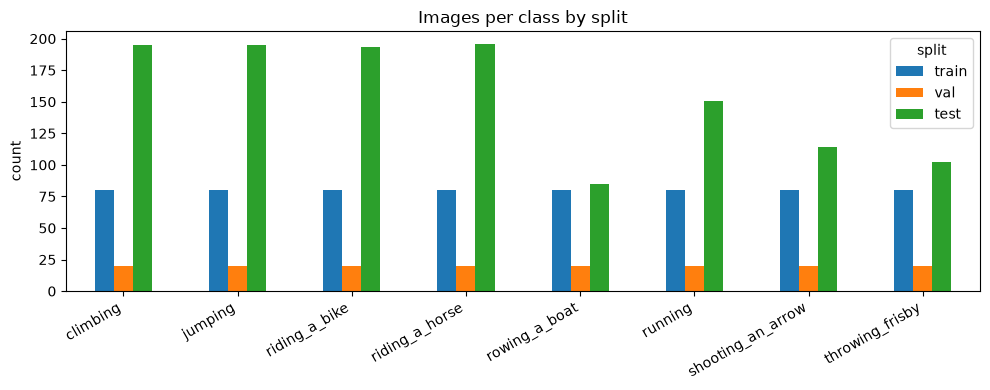

Test 가장 많은 클래스: riding_a_horse 196장 / 가장 적은 클래스: rowing_a_boat 85장 → 2.31배 차이

[가정] 'rowing_a_boat'를 전부 틀리면 → Accuracy는 최대 6.9%p만 하락, 하지만 Macro 지표는 클래스 하나 몫인 약 12.5%p 하락


In [3]:
dist = pd.crosstab(meta["class_name"], meta["split"]).reindex(CLASS_NAMES)[SPLITS]
dist["test 비율(%)"] = (dist["test"] / dist["test"].sum() * 100).round(1)
display(dist)

fig, ax = plt.subplots(figsize=(10, 4))
dist[SPLITS].plot.bar(ax=ax)
ax.set_title("Images per class by split")
ax.set_ylabel("count"); ax.set_xlabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.savefig(FIG_DIR / "01_class_distribution.png"); plt.show()

t = dist["test"]
print(f"Test 가장 많은 클래스: {t.idxmax()} {t.max()}장 / 가장 적은 클래스: {t.idxmin()} {t.min()}장 → {t.max()/t.min():.2f}배 차이")

# Accuracy만 보면 왜 위험한지 숫자로 보여주기:
# 가장 적은 클래스를 '전부 틀린다'고 가정했을 때 Accuracy와 Macro 지표가 얼마나 떨어지는지
smallest = t.idxmin()
acc_drop = t.min() / t.sum() * 100
print(f"\n[가정] '{smallest}'를 전부 틀리면 → Accuracy는 최대 {acc_drop:.1f}%p만 하락,"
      f" 하지만 Macro 지표는 클래스 하나 몫인 약 {100/len(CLASS_NAMES):.1f}%p 하락")

**해석 가이드 (보고서 문장 예시)**
> Train/Validation은 클래스별 80/20장으로 균형이지만 Test는 클래스별 최대 약 2.3배 차이가 나는 불균형 분포다. Accuracy는 장수가 많은 클래스의 영향을 크게 받아 적은 클래스(예: 보트 노 젓기)를 놓쳐도 크게 떨어지지 않으므로, 모든 클래스를 똑같은 무게로 평균 내는 **Macro F1**을 핵심 지표로 선정하고 Accuracy·클래스별 Precision/Recall·Confusion Matrix를 함께 본다.

- **Macro F1** = 클래스마다 F1(정밀도와 재현율의 조화 평균)을 따로 구한 뒤 단순 평균. 클래스 크기와 상관없이 8개 행동을 공평하게 본다.

## 3 · 해상도와 종횡비
- **종횡비(aspect ratio)** = 가로 ÷ 세로. 1보다 크면 가로로 긴 사진, 작으면 세로로 긴 사진.
- 모델 입력은 224×224 정사각형이라, 원본 모양에 따라 잘리거나(Crop) 여백(Padding)이 생긴다.

,width,height,aspect,file_size_bytes
count,2031.00,2031.00,2031.00,2031.00
mean,434.76,421.42,1.10,81219.63
std,151.06,151.04,0.36,47946.74
min,200.00,200.00,0.46,12856.00
25%,300.00,300.00,0.73,50443.00
50%,400.00,400.00,1.15,67376.00
75%,500.00,479.00,1.42,97162.50
max,926.00,960.00,2.79,382854.00


짧은 변 < 224px: 176 장 / 긴 변 < 224px: 24 장

[클래스별 사진 방향 비율(%)]


shape,landscape,portrait,square
class_name,,,
climbing,28.5,69.2,2.4
jumping,42.4,53.9,3.7
riding_a_bike,50.9,42.0,7.2
riding_a_horse,66.9,29.1,4.1
rowing_a_boat,91.4,7.0,1.6
running,37.8,58.2,4.0
shooting_an_arrow,66.8,29.0,4.2
throwing_frisby,55.4,38.6,5.9


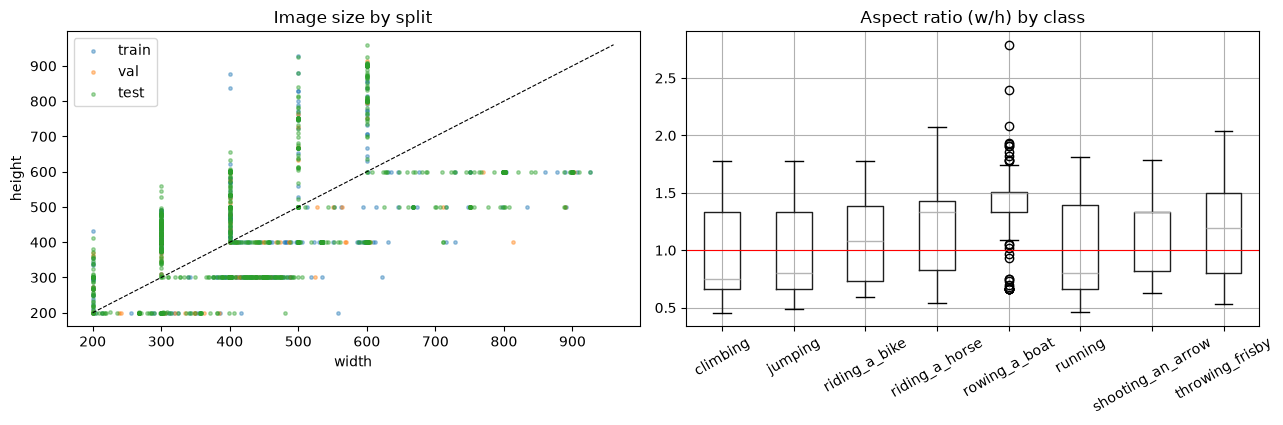

In [4]:
meta["aspect"] = meta["width"] / meta["height"]
meta["short_side"] = meta[["width", "height"]].min(axis=1)
meta["long_side"] = meta[["width", "height"]].max(axis=1)
meta["shape"] = np.select([meta["aspect"] > 1.05, meta["aspect"] < 0.95], ["landscape", "portrait"], "square")

display(meta[["width", "height", "aspect", "file_size_bytes"]].describe().round(2))
print("짧은 변 < 224px:", (meta["short_side"] < 224).sum(), "장 / 긴 변 < 224px:", (meta["long_side"] < 224).sum(), "장")
print("\n[클래스별 사진 방향 비율(%)]")
display((pd.crosstab(meta["class_name"], meta["shape"], normalize="index") * 100).reindex(CLASS_NAMES).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
# (왼쪽) 가로·세로 크기 산점도: 분할별로 크기 분포가 비슷한지
for s in SPLITS:
    sub = meta[meta["split"] == s]
    axes[0].scatter(sub["width"], sub["height"], s=6, alpha=0.4, label=s)
axes[0].plot([200, 960], [200, 960], "k--", lw=0.8)  # 대각선 = 정사각형
axes[0].set_xlabel("width"); axes[0].set_ylabel("height"); axes[0].legend(); axes[0].set_title("Image size by split")
# (오른쪽) 클래스별 종횡비 상자그림: 클래스마다 사진 모양이 다른지
meta.boxplot(column="aspect", by="class_name", ax=axes[1], rot=30)
axes[1].axhline(1.0, color="red", lw=0.8)
axes[1].set_title("Aspect ratio (w/h) by class"); axes[1].set_xlabel("")
plt.suptitle("")
plt.tight_layout(); plt.savefig(FIG_DIR / "02_size_aspect.png"); plt.show()

**해석 가이드**
- 클래스별 종횡비가 뚜렷이 다르면(예: 등반·점프·달리기는 세로형, 보트·승마·활쏘기는 가로형) 두 가지를 기록해 둔다.
  1. **Crop 위험:** 가로로 긴 사진을 정사각형으로 자르면 양 끝의 노·활·말이 잘릴 수 있다.
  2. **지름길 학습 가능성:** Padding을 쓰면 여백 모양(위아래 vs 좌우)에 사진 방향이 드러난다. 모델이 행동 대신 "여백 모양"을 단서로 쓸 가능성이 있으므로, 나중에 오분류 분석에서 점검할 **가설**로 남긴다. (지금 단정하지 않는다)
- 짧은 변이 224보다 작은 사진은 확대되며 흐려질 수 있다. 작은 도구(원반)가 더 안 보일 수 있으니 오분류 분석 때 참고한다.

## 4 · 손상·색상·밝기 점검 (전체 이미지 열기)
모든 이미지를 실제로 열어 본다. 시간은 수 분 정도 걸릴 수 있다.
- **손상:** 파일이 깨져서 열리지 않는 경우
- **색 모드:** RGB가 아닌 흑백(L), CMYK 등은 학습 전에 RGB로 바꿔야 한다
- 이 단계에서 다음 섹션(중복 탐지)에 쓸 **지문(hash)**도 함께 계산한다

In [5]:
def dhash_bits(img, size=8):
    """사진을 9x8 흑백으로 줄인 뒤 옆 픽셀보다 밝은지(1)/어두운지(0)를 64칸으로 기록 → 사진의 '지문'.
    비슷한 사진은 지문도 비슷해서, 크기·압축이 조금 달라도 중복을 찾을 수 있다."""
    g = np.asarray(img.convert("L").resize((size + 1, size), Image.BILINEAR), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()

records, hashes, hashes_flip = [], [], []
for row in tqdm(meta.itertuples(), total=len(meta)):
    path = DATA_DIR / row.image_path
    rec = {"image_id": row.image_id, "ok": True, "mode": None, "real_w": None, "real_h": None,
           "md5": None, "gray_like": None, "brightness": None}
    try:
        with Image.open(path) as im:
            im.verify()                                   # 파일 구조가 깨졌는지 1차 검사
        with Image.open(path) as im:                      # verify 후에는 다시 열어야 함
            im.load()                                     # 픽셀까지 실제로 읽어 2차 검사
            rec["mode"] = im.mode
            rec["real_w"], rec["real_h"] = im.size
            rgb = im.convert("RGB")
            small = np.asarray(rgb.resize((64, 64)), dtype=np.int16)
            # R,G,B 값 차이가 거의 없으면 겉보기는 RGB여도 사실상 흑백 사진
            rec["gray_like"] = bool(np.abs(small[..., 0] - small[..., 1]).mean() < 2 and
                                    np.abs(small[..., 1] - small[..., 2]).mean() < 2)
            rec["brightness"] = float(small.mean())       # 0(검정)~255(흰색) 평균 밝기
            hashes.append(dhash_bits(rgb))
            hashes_flip.append(dhash_bits(rgb.transpose(Image.FLIP_LEFT_RIGHT)))  # 좌우 반전 중복용
        rec["md5"] = hashlib.md5(path.read_bytes()).hexdigest()  # 파일 내용이 '완전히' 같은지 확인용
    except Exception as e:
        rec["ok"] = False; rec["error"] = str(e)
        hashes.append(np.zeros(64, bool)); hashes_flip.append(np.zeros(64, bool))
    records.append(rec)

qc = meta.merge(pd.DataFrame(records), on="image_id")
print("열리지 않는(손상) 이미지:", (~qc["ok"]).sum())
if (~qc["ok"]).any(): display(qc.loc[~qc["ok"], ["image_id", "split", "class_name", "image_path", "error"]])
ok_qc = qc[qc["ok"]]                                         # 이하 집계는 정상적으로 열린 이미지만 대상
print("메타데이터와 실제 크기가 다른 이미지:", ((ok_qc["width"] != ok_qc["real_w"]) | (ok_qc["height"] != ok_qc["real_h"])).sum())
print("\n[색 모드별 개수]"); print(ok_qc["mode"].value_counts())
print("\n사실상 흑백인 사진:", qc["gray_like"].sum(), "장")
display(pd.crosstab(qc["class_name"], qc["gray_like"]).reindex(CLASS_NAMES))

  0%|          | 0/2031 [00:00<?, ?it/s]

열리지 않는(손상) 이미지: 0
메타데이터와 실제 크기가 다른 이미지: 0

[색 모드별 개수]
mode
RGB    2031
Name: count, dtype: int64

사실상 흑백인 사진: 0 장


gray_like,False
class_name,
climbing,295
jumping,295
riding_a_bike,293
riding_a_horse,296
rowing_a_boat,185
running,251
shooting_an_arrow,214
throwing_frisby,202


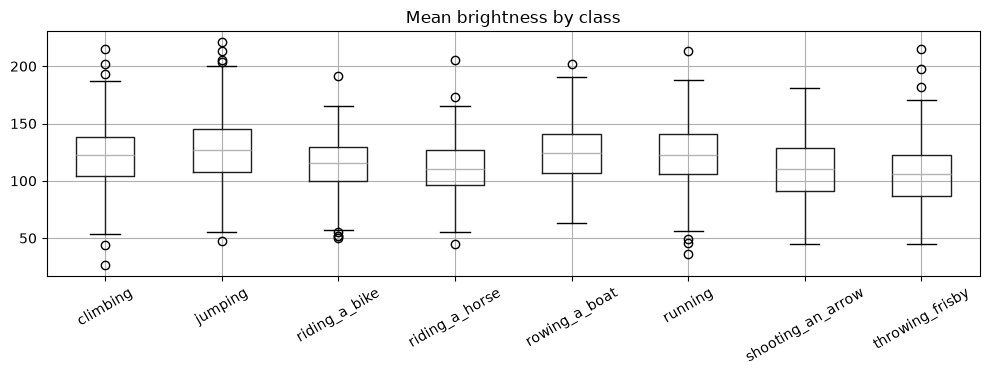

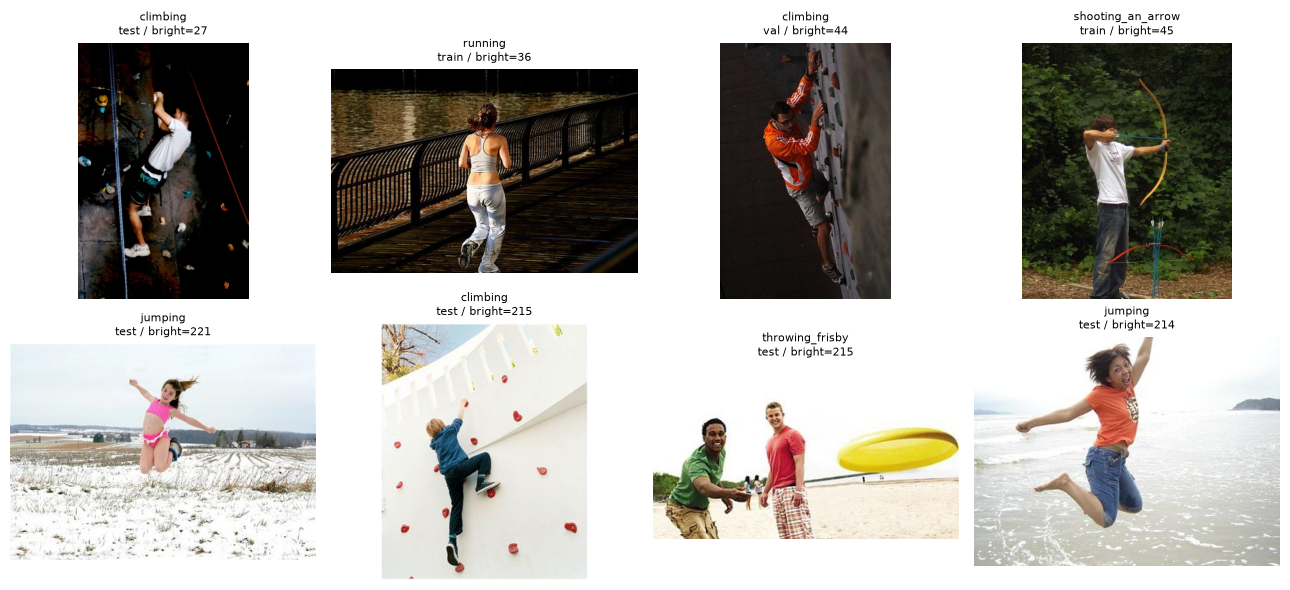

In [6]:
# 클래스별 밝기 분포 (손상 이미지는 밝기 값이 없어 자동 제외): 특정 클래스만 유난히 밝거나 어두우면 '배경 의존' 가능성의 단서
fig, ax = plt.subplots(figsize=(10, 4))
qc.boxplot(column="brightness", by="class_name", ax=ax, rot=30)
ax.set_title("Mean brightness by class"); ax.set_xlabel(""); plt.suptitle("")
plt.tight_layout(); plt.savefig(FIG_DIR / "03_brightness.png"); plt.show()

# 너무 어둡거나 밝은 사진 몇 장 눈으로 확인
extremes = pd.concat([qc.nsmallest(4, "brightness"), qc.nlargest(4, "brightness")])
fig, axes = plt.subplots(2, 4, figsize=(13, 6))
for ax, r in zip(axes.flat, extremes.itertuples()):
    ax.imshow(load_rgb(r.image_path))
    ax.set_title(f"{r.class_name}\n{r.split} / bright={r.brightness:.0f}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

## 5 · 중복·유사 이미지 점검 (데이터 누수 확인)
**데이터 누수(leakage)** = 시험 문제(Test)를 미리 공부(Train)한 상태. Train/Val과 Test에 같은 사진이 있으면 Test 점수가 실제보다 좋게 나온다.
- **완전 중복:** 파일 내용(md5)이 같은 경우
- **유사 중복:** 지문(dHash) 64칸 중 다른 칸이 아주 적은 경우 (크기만 다르거나, 재압축, 좌우 반전 등)
- 지문은 후보를 찾는 도구일 뿐이다. **최종 판단은 반드시 눈으로** 한다.

In [7]:
# 완전 중복
dup_md5 = qc[qc["md5"].duplicated(keep=False)].sort_values("md5")
print("파일 내용이 완전히 같은 이미지:", len(dup_md5), "장")
if len(dup_md5): display(dup_md5[["image_id", "split", "class_name", "source_filename", "md5"]])

# 유사 중복: 지문을 +1/-1로 바꾸면 행렬 곱 한 번으로 모든 쌍의 '다른 칸 수'를 계산할 수 있다
H  = np.where(np.array(hashes), 1, -1).astype(np.float32)
Hf = np.where(np.array(hashes_flip), 1, -1).astype(np.float32)
dist_same = (64 - H @ H.T) / 2          # 그대로 비교
dist_flip = (64 - H @ Hf.T) / 2         # 한쪽을 좌우 반전해서 비교
dist_all = np.minimum(dist_same, dist_flip)

THRESH = 6                               # 64칸 중 6칸 이하로 다르면 '유사 후보' (조정 가능)
ok = qc["ok"].values                                       # 손상 이미지는 지문이 없으므로 비교에서 제외
valid = ok[:, None] & ok[None, :]
i_idx, j_idx = np.where(np.triu((dist_all <= THRESH) & valid, k=1))   # 같은 쌍을 두 번 세지 않도록 위쪽 삼각형만
pairs = pd.DataFrame({
    "a": qc["image_id"].values[i_idx], "b": qc["image_id"].values[j_idx],
    "split_a": qc["split"].values[i_idx], "split_b": qc["split"].values[j_idx],
    "class_a": qc["class_name"].values[i_idx], "class_b": qc["class_name"].values[j_idx],
    "dist": dist_all[i_idx, j_idx].astype(int),
    "flipped": (dist_flip[i_idx, j_idx] < dist_same[i_idx, j_idx]),
})
# 분할이 다른 쌍 중 한쪽이 test면 누수 위험
pairs["leak_risk"] = (pairs["split_a"] != pairs["split_b"]) & ((pairs["split_a"] == "test") | (pairs["split_b"] == "test"))
pairs["label_conflict"] = pairs["class_a"] != pairs["class_b"]   # 같은 사진인데 라벨이 다르면 라벨 오류 의심
pairs = pairs.sort_values(["leak_risk", "dist"], ascending=[False, True])
print(f"유사 후보 쌍: {len(pairs)}개 (Test 누수 위험: {pairs['leak_risk'].sum()}, 라벨 충돌: {pairs['label_conflict'].sum()})")
display(pairs.head(20))
pairs.to_csv(FIG_DIR / "near_duplicate_candidates.csv", index=False)

파일 내용이 완전히 같은 이미지: 0 장
유사 후보 쌍: 4개 (Test 누수 위험: 2, 라벨 충돌: 2)


,a,b,split_a,split_b,class_a,class_b,dist,flipped,leak_risk,label_conflict
3,s40_21b8df1d9d9c4dded03f,s40_ca7ab8e14b30f790812e,val,test,running,climbing,4,False,True,True
0,s40_10cf825ec96bc7c6b82c,s40_5cc4849ce749f204ee96,train,test,jumping,jumping,6,True,True,False
1,s40_21b8df1d9d9c4dded03f,s40_65cc43e103a23fe243d3,val,train,running,running,3,False,False,False
2,s40_21b8df1d9d9c4dded03f,s40_8f760b0952305f0ad06d,val,train,running,jumping,6,False,False,True


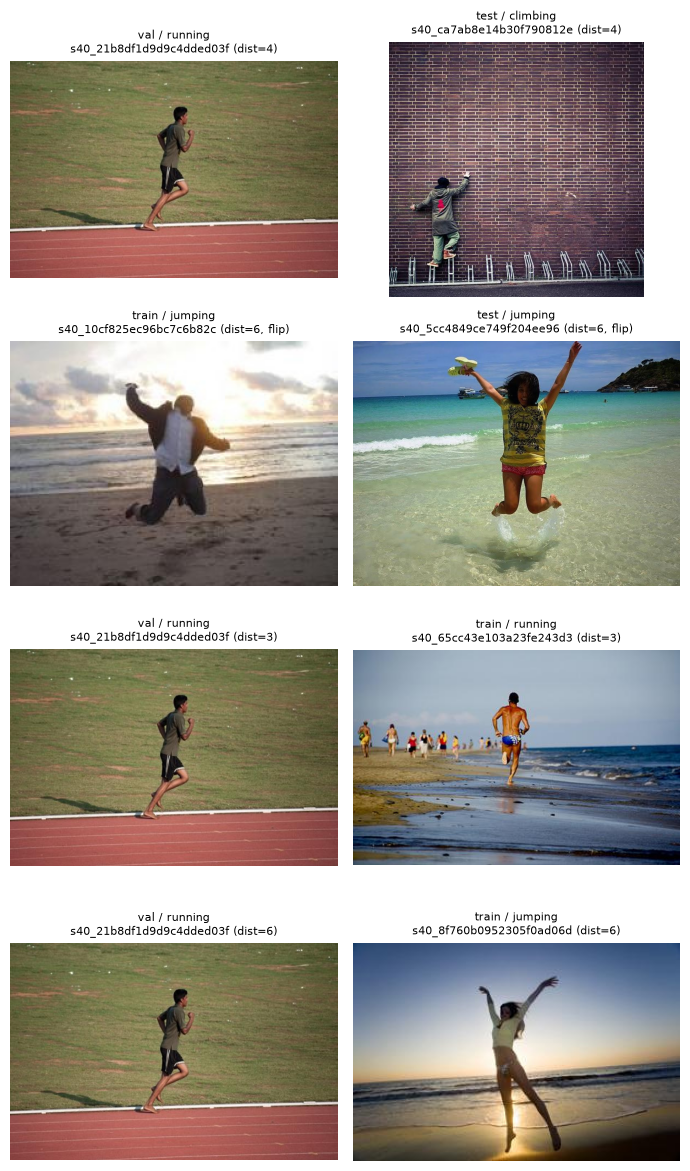

In [8]:
# 후보 쌍을 나란히 보여주기 (최대 8쌍)
show = pairs.head(8)
if len(show) == 0:
    print("유사 후보가 없습니다.")
else:
    path_of = qc.set_index("image_id")["image_path"]
    fig, axes = plt.subplots(len(show), 2, figsize=(7, 3 * len(show)), squeeze=False)
    for k, r in enumerate(show.itertuples()):
        for c, (iid, sp, cl) in enumerate([(r.a, r.split_a, r.class_a), (r.b, r.split_b, r.class_b)]):
            axes[k, c].imshow(load_rgb(path_of[iid]))
            axes[k, c].set_title(f"{sp} / {cl}\n{iid} (dist={r.dist}{', flip' if r.flipped else ''})", fontsize=8)
            axes[k, c].axis("off")
    plt.tight_layout(); plt.savefig(FIG_DIR / "04_near_duplicates.png"); plt.show()

**해석 가이드**
- 눈으로 봐서 **진짜 같은 사진**인 쌍만 "중복"으로 기록한다. 구도가 비슷한 다른 사진(예: 비슷한 암벽)은 중복이 아니다.
- 진짜 중복이 Train/Val ↔ Test 사이에 있다면 **임의로 지우지 말고 먼저 튜터에게 공유**한다. 분할은 과제에서 고정된 조건이라 팀이 마음대로 바꾸면 비교 기준이 흔들린다.
- 결과가 0건이어도 "어떤 방법으로 확인했고 0건이었다"는 것 자체가 보고서의 근거가 된다.

## 6 · 클래스별 샘플 눈으로 보기
Train에서 클래스마다 6장씩 무작위로 본다. 아래 **관찰 질문**을 메모하며 본다.

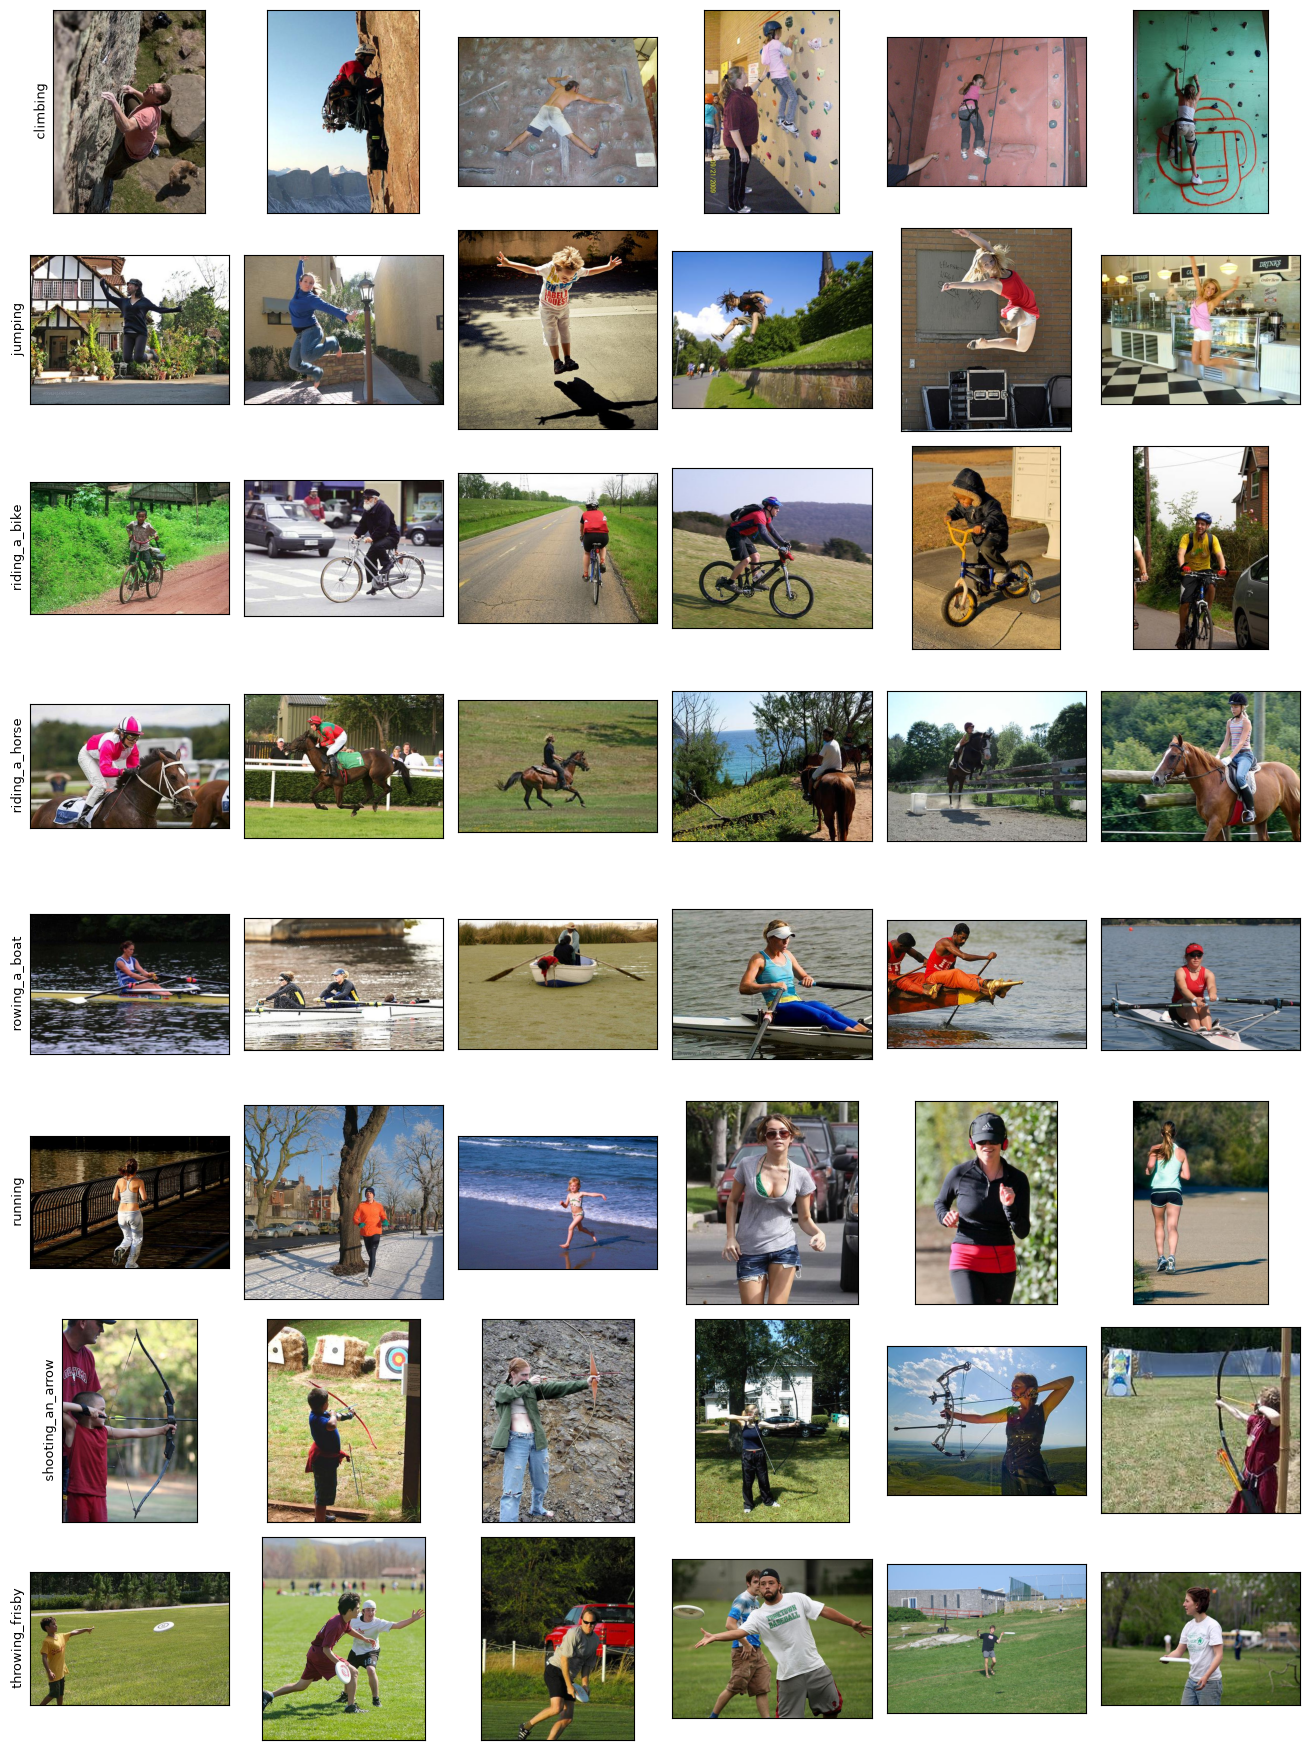

In [9]:
N_PER = 6
train_meta = meta[meta["split"] == "train"]
fig, axes = plt.subplots(len(CLASS_NAMES), N_PER, figsize=(N_PER * 2.2, len(CLASS_NAMES) * 2.2))
for r_i, cname in enumerate(CLASS_NAMES):
    sample = train_meta[train_meta["class_name"] == cname].sample(N_PER, random_state=SEED)
    for c_i, row in enumerate(sample.itertuples()):
        ax = axes[r_i, c_i]
        ax.imshow(load_rgb(row.image_path))
        ax.set_xticks([]); ax.set_yticks([])
        if c_i == 0: ax.set_ylabel(cname, fontsize=9)
plt.tight_layout(); plt.savefig(FIG_DIR / "05_class_samples.png"); plt.show()

**관찰 질문 (팀원끼리 나눠서 메모)**
1. 점프와 달리기는 사진 한 장으로 구분이 되는가? 사람이 봐도 헷갈리는 사진이 있는가?
2. 프리스비 원반은 사진에서 얼마나 크게 보이는가? 224×224로 줄이면 보일까?
3. 활·노·자전거처럼 **행동을 결정하는 도구**가 사진 가장자리에 있는 경우가 많은가? (→ Crop 위험)
4. 배경만 보고도 맞힐 수 있는 클래스가 있는가? (물 → 보트, 암벽 → 등반, 잔디 → 프리스비?) (→ 배경 의존 가설)
5. 사람이 아주 작게 나오거나 여러 명인 사진이 있는가?

## 7 · 전처리 비교: Center Crop vs Resize + Padding
- **Center Crop:** 짧은 변을 맞춘 뒤 가운데를 정사각형으로 잘라냄 → 화면은 꽉 차지만 가장자리가 잘림
- **Resize + Padding:** 긴 변을 224에 맞추고 남는 곳을 여백으로 채움 → 아무것도 안 잘리지만 대상이 작아짐
- 여백 색은 ImageNet 평균색 (124, 116, 104)을 쓴다. 정규화하면 거의 0이 되어 "정보 없음"에 가까운 값이 되기 때문이다.

아래 `resize_with_padding` 함수는 다음 단계(전처리 노트북)에서도 그대로 재사용한다.

In [10]:
IMAGENET_MEAN_RGB = (124, 116, 104)   # ImageNet 평균(0.485, 0.456, 0.406) × 255

def resize_with_padding(img, size=224, fill=IMAGENET_MEAN_RGB):
    """종횡비를 유지한 채 긴 변을 size에 맞추고, 남는 공간을 fill 색으로 채워 정사각형으로 만든다."""
    w, h = img.size
    scale = size / max(w, h)
    nw, nh = max(1, round(w * scale)), max(1, round(h * scale))
    resized = img.resize((nw, nh), Image.BICUBIC)
    canvas = Image.new("RGB", (size, size), fill)
    canvas.paste(resized, ((size - nw) // 2, (size - nh) // 2))   # 가운데에 붙이기
    return canvas

def center_crop(img, size=224, resize_to=256):
    """torchvision 기본 평가 방식(Resize 256 → CenterCrop 224)을 흉내 낸 함수."""
    w, h = img.size
    scale = resize_to / min(w, h)
    img = img.resize((round(w * scale), round(h * scale)), Image.BICUBIC)
    w, h = img.size
    left, top = (w - size) // 2, (h - size) // 2
    return img.crop((left, top, left + size, top + size))

# 숫자로 비교: 각 방식이 원본의 몇 %를 잃는지 / 입력의 몇 %가 여백인지
r = np.maximum(meta["aspect"], 1 / meta["aspect"])        # 1 이상으로 맞춘 길쭉한 정도
meta["crop_lost_%"] = (1 - (224 / 256) ** 2 / r) * 100   # Center Crop으로 잘려나가는 원본 면적 비율
meta["pad_area_%"] = (1 - 1 / r) * 100                     # Padding 방식에서 여백이 차지하는 비율
display(meta.groupby("class_name")[["crop_lost_%", "pad_area_%"]].mean().reindex(CLASS_NAMES).round(1))

,crop_lost_%,pad_area_%
class_name,,
climbing,45.0,28.1
jumping,45.0,28.2
riding_a_bike,43.0,25.5
riding_a_horse,43.7,26.4
rowing_a_boat,47.1,30.9
running,45.5,28.8
shooting_an_arrow,43.0,25.5
throwing_frisby,42.6,25.0


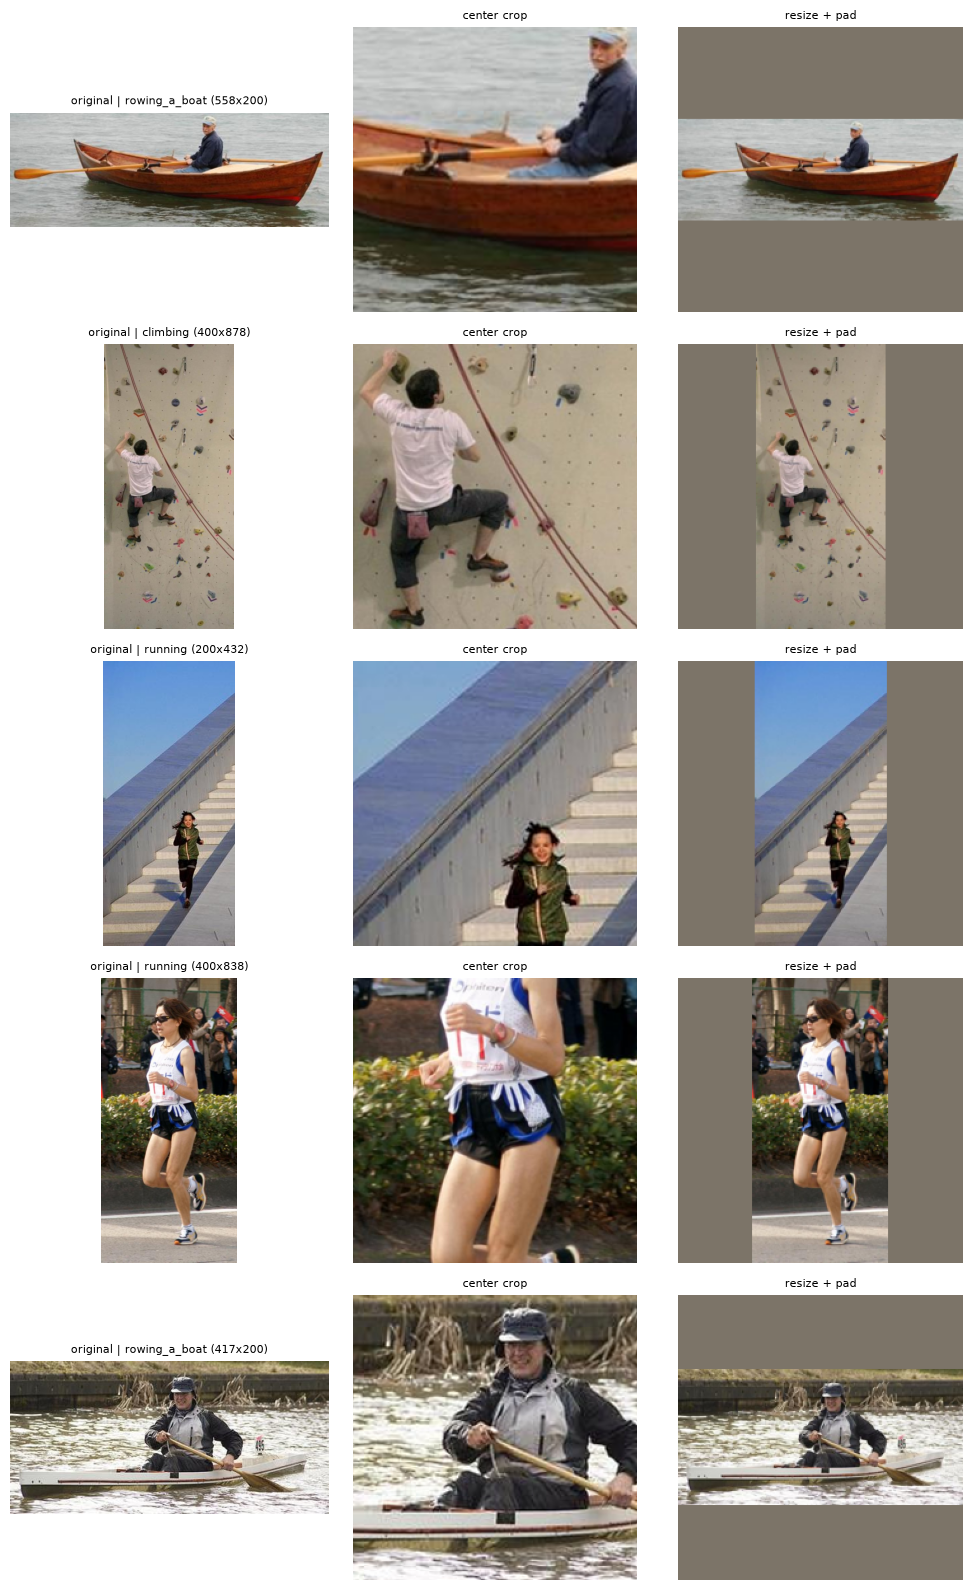

In [11]:
# 가장 길쭉한 Train 사진들로 세 가지를 나란히 보기
wide = meta[meta["split"] == "train"].assign(r=r).nlargest(5, "r")
fig, axes = plt.subplots(len(wide), 3, figsize=(10, 3.2 * len(wide)))
for k, row in enumerate(wide.itertuples()):
    im = load_rgb(row.image_path)
    for c, (title, view) in enumerate([("original", im), ("center crop", center_crop(im)),
                                       ("resize + pad", resize_with_padding(im))]):
        axes[k, c].imshow(view); axes[k, c].axis("off")
        axes[k, c].set_title(f"{title}" + (f" | {row.class_name} ({row.width}x{row.height})" if c == 0 else ""), fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "06_crop_vs_pad.png"); plt.show()

**해석 가이드 (보고서 문장 예시)**
> 이미지의 종횡비는 0.46~2.79로 다양하고 클래스마다 주된 방향이 달랐다. 표준 Center Crop은 가로형 사진이 많은 클래스에서 원본의 상당 부분을 잘라내어 노·활 같은 핵심 도구가 사라지는 사례가 확인되었다. 따라서 정보 손실이 없는 **종횡비 유지 Resize + Padding(224×224)**을 기본 전처리로 정하고, 대상이 작아지는 단점과 여백 모양이 단서가 될 가능성은 오분류 분석에서 점검한다.

## 8 · EDA 요약 저장
이후 노트북과 보고서에서 다시 쓰도록 핵심 수치를 파일로 남긴다.

In [12]:
summary = {
    "총 이미지": len(meta),
    "train/val/test": "/".join(str((meta["split"] == s).sum()) for s in SPLITS),
    "Test 최대/최소 클래스 비": round(dist["test"].max() / dist["test"].min(), 2),
    "라벨 연결 불일치": checks["파일명-라벨 불일치"],
    "손상 이미지": int((~qc["ok"]).sum()),
    "RGB 아닌 모드": int((qc["ok"] & (qc["mode"] != "RGB")).sum()),
    "사실상 흑백": int(qc["gray_like"].sum()),
    "완전 중복(장)": len(dup_md5),
    "유사 후보 쌍": len(pairs),
    "Test 누수 위험 후보 쌍": int(pairs["leak_risk"].sum()),
    "종횡비 범위": f'{meta["aspect"].min():.2f}~{meta["aspect"].max():.2f}',
    "짧은 변<224": int((meta["short_side"] < 224).sum()),
}
summary_df = pd.Series(summary, name="value").to_frame()
display(summary_df)
summary_df.to_csv(FIG_DIR / "eda_summary.csv", encoding="utf-8-sig")
qc.drop(columns=["md5"]).to_csv(FIG_DIR / "image_quality_table.csv", index=False, encoding="utf-8-sig")
print("저장 완료 →", FIG_DIR.resolve())

,value
총 이미지,2031
train/val/test,640/160/1231
Test 최대/최소 클래스 비,2.31
라벨 연결 불일치,0
손상 이미지,0
RGB 아닌 모드,0
사실상 흑백,0
완전 중복(장),0
유사 후보 쌍,4
Test 누수 위험 후보 쌍,2


저장 완료 → C:\Users\power\Documents\human-action-classification\figures
